In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_nfw import build_model, halofit

<Axes: title={'center': 'Stack result'}, xlabel='X', ylabel='Y'>

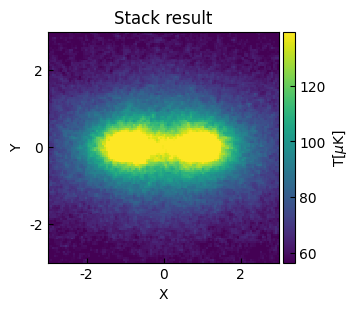

In [4]:
coord = get_coord()

data = np.load('../data/tng_pairstack_result.npz', 'r')['data']
plot_heatmap(data, title='Stack result')

In [24]:
tolenrance = 0.05

bounds = {
    'amplitude_0': (0, 200),
    'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
}

constraints = {
        "fixed": [
            "x_mean_0",
            "y_mean_0",
            "x_mean_1",
            "y_mean_1",
        ],  # fix the center of the two NFW profiles
        "tied": [
            ("amplitude_1", "amplitude_0")  # amplitude_1 = amplitude_0
        ],
    }

model = build_model(bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... r_s_1 ellipticity_1 theta_1 amplitude_2
    ----------- -------- -------- ----- ... ----- ------------- ------- -----------
           50.0     -1.0      0.0   0.5 ...   0.5           0.0     0.0         0.0


# without mask

In [25]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=2.52989142, x_mean=-1., y_mean=0., r_s=17.73799683, ellipticity=0.22614553, theta=-0.0216737)>

    [1]: <NFW2D(amplitude=2.52989142, x_mean=1., y_mean=0., r_s=17.67395234, ellipticity=0.22674958, theta=-0.01776669)>

    [2]: <Const2D(amplitude=44.02162186)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...        theta_1           amplitude_2    
    ----------------- -------- -------- ... --------------------- ------------------
    2.529891415153843     -1.0      0.0 ... -0.017766693227983948 44.021621862550326

Goodness of fit:
Chi-squared: 4182175.854
RMS residual: 17.042


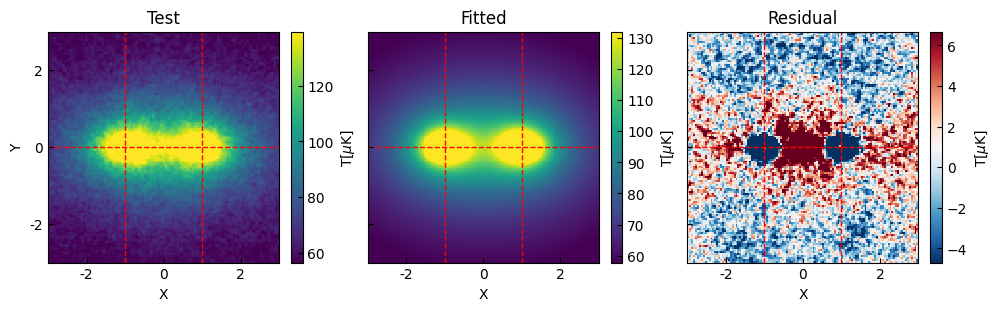

In [26]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

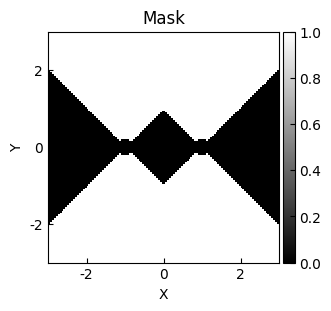

In [27]:
mask = get_mask_sector(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [28]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=0.57090828, x_mean=-1., y_mean=0., r_s=94.1098347, ellipticity=0.43594327, theta=62.80594708)>

    [1]: <NFW2D(amplitude=0.57090828, x_mean=1., y_mean=0., r_s=90.14741479, ellipticity=0.41982332, theta=3.12469604)>

    [2]: <Const2D(amplitude=40.15675802)>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...      theta_1          amplitude_2   
    ------------------ -------- -------- ... ------------------ -----------------
    0.5709082835730951     -1.0      0.0 ... 3.1246960415282152 40.15675801839213

Goodness of fit:
Chi-squared: 4789287.364
RMS residual: 18.237


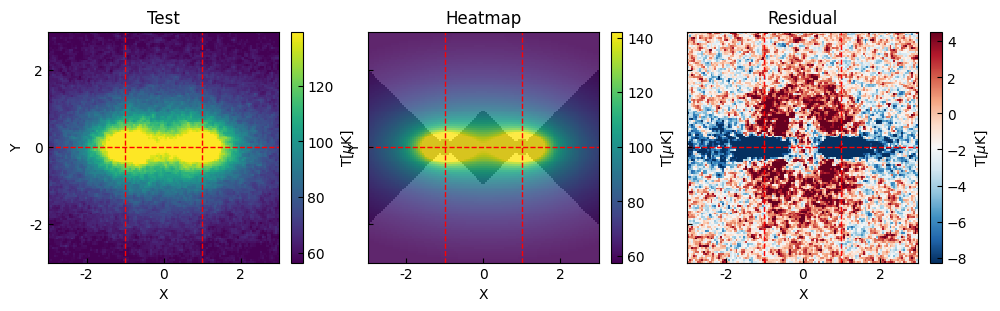

In [29]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

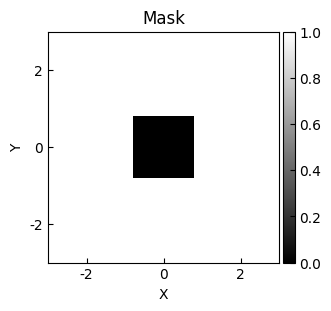

In [30]:
mask = ~get_mask_square(coord=coord, xlim=[-0.8, 0.8], ylim=[-0.8, 0.8])
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [31]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=7.37483688, x_mean=-1., y_mean=0., r_s=6.17120414, ellipticity=0.21501628, theta=75.37638169)>

    [1]: <NFW2D(amplitude=7.37483688, x_mean=1., y_mean=0., r_s=6.15511566, ellipticity=0.21549272, theta=62.81128455)>

    [2]: <Const2D(amplitude=51.83473879)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...      theta_1         amplitude_2   
    ----------------- -------- -------- ... ----------------- -----------------
    7.374836875387759     -1.0      0.0 ... 62.81128455140559 51.83473879121164

Goodness of fit:
Chi-squared: 4228373.304
RMS residual: 17.136


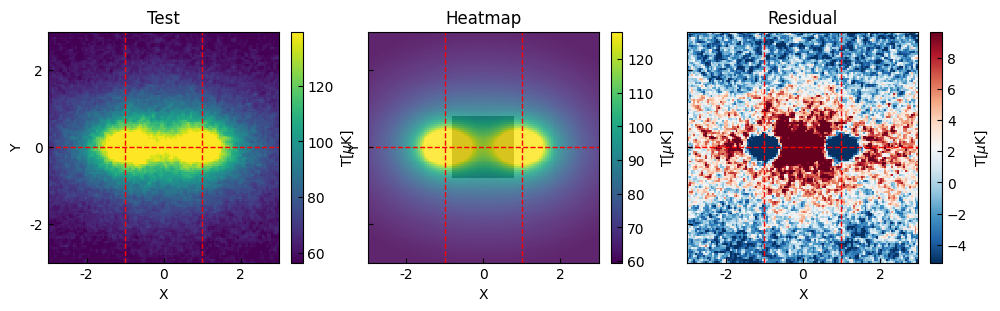

In [32]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [33]:
from mytools.plot import plot_hist

(-50.0, 50.0)

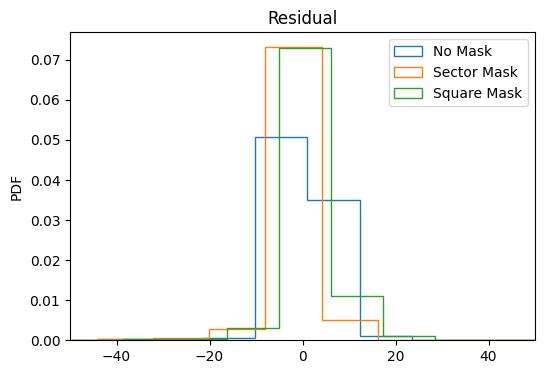

In [34]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
title = ['No Mask', 'Sector Mask', 'Square Mask']
ax = plot_hist(res_list, label=title, bins=100, title='Residual')
ax.set_xlim(-50, 50)